<a href="https://colab.research.google.com/github/Harsitha05/my-academic-projects/blob/main/ml_mini_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CUSTOMER SEGMENTATION - MARKETING INTELLIGENCE

Dataset: 200 customers, 5 features
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Optimal K = 5 (Silhouette: 0.5547)


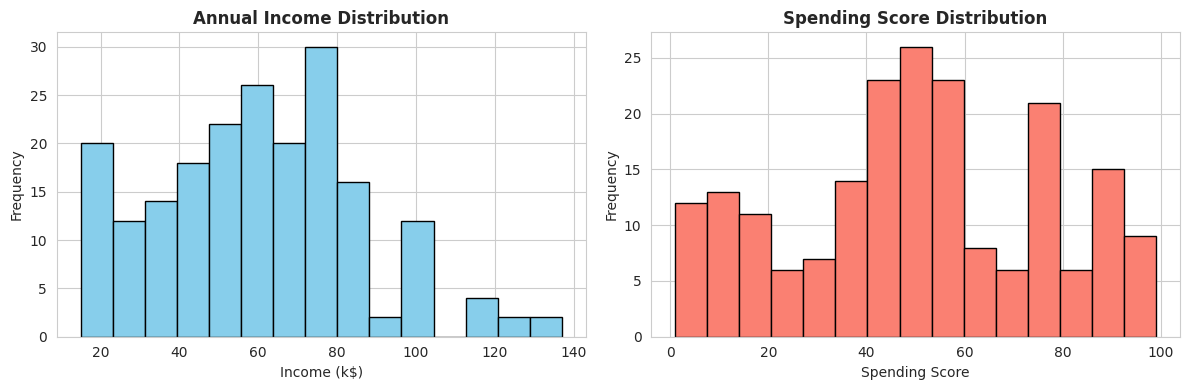

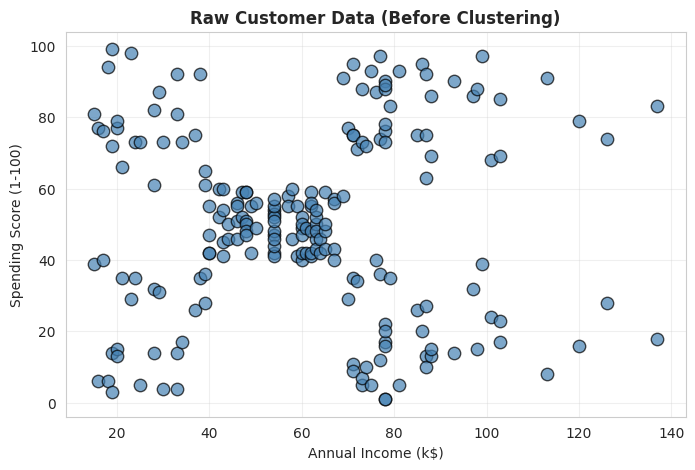

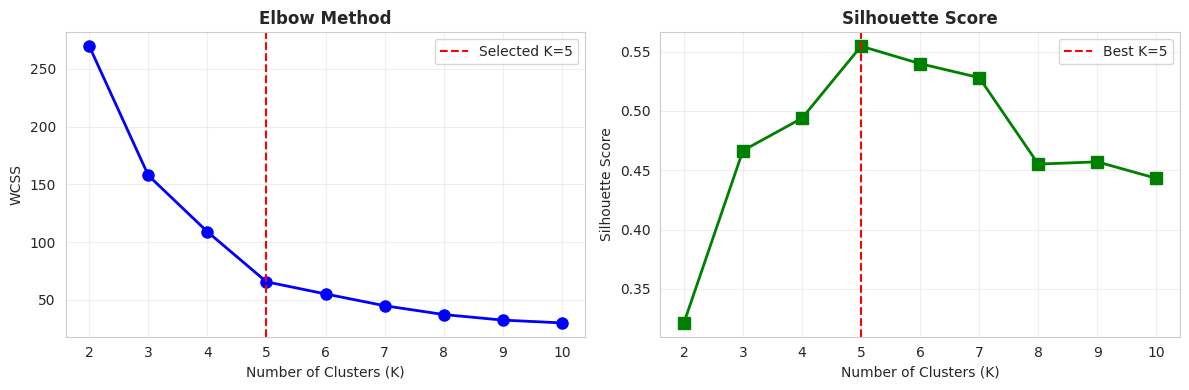

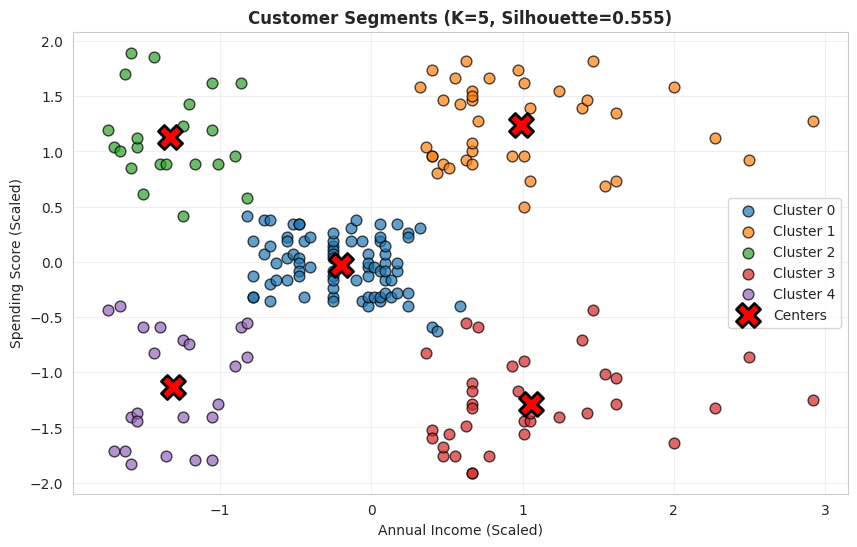


RESULTS SUMMARY

--- CLUSTER CENTERS ---
   Income (k$)  Spending Score
0    55.296296       49.518519
1    86.538462       82.128205
2    25.727273       79.363636
3    88.200000       17.114286
4    26.304348       20.913043

--- CLUSTER SIZES ---
Cluster 0: 81 customers (40.5%)
Cluster 1: 39 customers (19.5%)
Cluster 2: 22 customers (11.0%)
Cluster 3: 35 customers (17.5%)
Cluster 4: 23 customers (11.5%)

--- PERFORMANCE METRICS ---
Number of Clusters: 5
Silhouette Score: 0.5547
Inertia (WCSS): 65.57

✅ Saved: Segmented_Customers.csv

PROJECT COMPLETE


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

print("="*60)
print("CUSTOMER SEGMENTATION - MARKETING INTELLIGENCE")
print("="*60)

# 1. LOAD DATASET
df = pd.read_csv('/content/Mall_Customers.csv')
print(f"\nDataset: {df.shape[0]} customers, {df.shape[1]} features")
print(df.head())

# 2. FEATURE SELECTION & SCALING
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. FIND OPTIMAL K (Elbow + Silhouette)
wcss = []
sil_scores = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    wcss.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

best_k = K_range[np.argmax(sil_scores)]
print(f"\nOptimal K = {best_k} (Silhouette: {max(sil_scores):.4f})")

# ============================================
# PLOT 1: Distribution of Features (2 subplots)
# ============================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['Annual Income (k$)'], bins=15, color='skyblue', edgecolor='black')
axes[0].set_title('Annual Income Distribution', fontweight='bold')
axes[0].set_xlabel('Income (k$)')
axes[0].set_ylabel('Frequency')

axes[1].hist(df['Spending Score (1-100)'], bins=15, color='salmon', edgecolor='black')
axes[1].set_title('Spending Score Distribution', fontweight='bold')
axes[1].set_xlabel('Spending Score')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# ============================================
# PLOT 2: Raw Data Scatter
# ============================================
plt.figure(figsize=(8, 5))
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'],
            c='steelblue', alpha=0.7, s=80, edgecolors='black')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Raw Customer Data (Before Clustering)', fontweight='bold')
plt.grid(True, alpha=0.3)
plt.show()

# ============================================
# PLOT 3: Elbow Method + Silhouette (Combined)
# ============================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Elbow
axes[0].plot(range(2, 11), wcss, marker='o', linewidth=2, markersize=8, color='blue')
axes[0].axvline(x=best_k, color='red', linestyle='--', label=f'Selected K={best_k}')
axes[0].set_title('Elbow Method', fontweight='bold')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('WCSS')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Silhouette
axes[1].plot(range(2, 11), sil_scores, marker='s', linewidth=2, markersize=8, color='green')
axes[1].axvline(x=best_k, color='red', linestyle='--', label=f'Best K={best_k}')
axes[1].set_title('Silhouette Score', fontweight='bold')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 4. APPLY K-MEANS
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Get cluster centers (original scale)
centers = scaler.inverse_transform(kmeans.cluster_centers_)

# ============================================
# PLOT 4: Final Clusters with Centers
# ============================================
plt.figure(figsize=(10, 6))

# Scatter points colored by cluster
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']
for i in range(best_k):
    mask = df['Cluster'] == i
    plt.scatter(X_scaled[mask, 0], X_scaled[mask, 1],
                c=colors[i % len(colors)], label=f'Cluster {i}', s=60, alpha=0.7, edgecolors='black')

# Plot cluster centers
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            c='red', marker='X', s=300, edgecolors='black', linewidths=2, label='Centers')

plt.title(f'Customer Segments (K={best_k}, Silhouette={max(sil_scores):.3f})', fontweight='bold')
plt.xlabel('Annual Income (Scaled)')
plt.ylabel('Spending Score (Scaled)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# ============================================
# RESULTS SUMMARY
# ============================================
print("\n" + "="*60)
print("RESULTS SUMMARY")
print("="*60)

# Cluster Centers
centers_df = pd.DataFrame(centers, columns=['Income (k$)', 'Spending Score'])
print("\n--- CLUSTER CENTERS ---")
print(centers_df)

# Cluster Sizes
print("\n--- CLUSTER SIZES ---")
for i in range(best_k):
    size = len(df[df['Cluster'] == i])
    print(f"Cluster {i}: {size} customers ({size/len(df)*100:.1f}%)")

# Final Metrics
print(f"\n--- PERFORMANCE METRICS ---")
print(f"Number of Clusters: {best_k}")
print(f"Silhouette Score: {max(sil_scores):.4f}")
print(f"Inertia (WCSS): {kmeans.inertia_:.2f}")

# Save
df.to_csv("Segmented_Customers.csv", index=False)
print("\n✅ Saved: Segmented_Customers.csv")
print("\n" + "="*60)
print("PROJECT COMPLETE")
print("="*60)